# Does the Walkability–Housing Value Relationship Hold Within Cities?

**An exploratory ZIP/ZCTA-level comparison of New York City, Washington, DC, and Chicago**

> **Project status:** This notebook preserves the current validated version of an inherited exploratory analysis. Data definitions and the research framing were refined during a technical audit and after preliminary results had been examined. The findings should therefore be read as descriptive and diagnostic evidence, not as a preregistered confirmatory test.

## Research Goal

This project examines whether ZIP/ZCTAs with greater use of walking, public transit, and bicycling for commuting consistently have higher housing values **within** New York City, Washington, DC, and Chicago—or whether the positive relationship visible in pooled data is mainly produced by differences **among** the three cities.

### Primary question

**Within these three core-city samples, how is a commuting-based walkability proxy associated with Zillow Home Value Index (ZHVI) after accounting for city context and selected socioeconomic characteristics?**

### Supporting questions

1. How do walkability and housing values differ across the cities, and which ZIP/ZCTAs are relatively walkable and affordable within the sample?
2. Does the walkability–housing relationship change across pooled, city-controlled, and city-specific specifications?
3. Do relationships learned from two cities predict housing values in a third, geographically unseen city?

### Why these cities?

New York City, Washington, DC, and Chicago are treated as **purposively selected comparative cases**, not as a representative sample of U.S. cities. All three are large, established core cities with mature public-transit systems, substantial pre-automobile development, and enough walking, transit, and bicycle commuting for a commute-mode proxy to vary meaningfully across ZIP/ZCTAs.

The comparison is informative because the cities also differ in housing costs, density, transit dependence, regional context, and ZIP/ZCTA composition. Those differences create a useful test of whether a pooled relationship persists within distinct urban settings and transfers across them.

The city choices originated in the inherited project. This rationale explains why the comparison is analytically useful; it does not imply that the cases were prespecified through systematic sampling, constitute a strict matched-case design, or support claims about all U.S. cities.

## Study Areas and Analytical Strategy

The study uses **core-city samples, not metropolitan statistical areas**:

- **New York City:** ZIPs assigned by Zillow to the five borough counties.
- **Washington, DC:** ZIPs with state `DC` and city `Washington`.
- **Chicago:** ZIPs with city `Chicago` in Cook County.

Zillow ZIP assignments and Census ZCTAs approximate these boundaries and are not neighborhood definitions. The notebook first validates and maps the data, then answers the supporting questions with descriptive tables, pooled and within-city correlations, robust OLS models with city indicators, exploratory cluster diagnostics, and a leave-one-city-out Lasso transfer test.

The walkability measure is a weighted **commute-mode proxy**, not an official Walk Score or a direct built-environment measure. The analysis is cross-sectional and estimates associations rather than causal effects.

# Imports and folder setup

In [53]:
# Standard-library imports handle environment variables and path-safe file access.
import os
from pathlib import Path

# Data, mapping, visualization, and statistical libraries support the full analysis workflow.
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import statsmodels.api as sm
from sklearn.cluster import KMeans
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    adjusted_rand_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def find_project_root(start=Path.cwd()):
    """Locate the repository root without assuming the notebook working directory."""
    # Search upward for files that uniquely identify this project.
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Run the notebook from inside the cloned repository."
    )


def add_figure_caption(fig, caption):
    """Place an explanatory caption below a Matplotlib figure."""
    # Reserve bottom space so the caption remains visible when the notebook renders the figure.
    fig.text(
        0.5,
        0.01,
        caption,
        ha="center",
        va="bottom",
        fontsize=9,
        color="dimgray",
        wrap=True,
    )


# Centralized paths keep every data read and write relative to the repository root.
PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
HOUSING_DIR = DATA_DIR / "housing"
ACS_DIR = DATA_DIR / "acs"
GEO_DIR = DATA_DIR / "geo"

# Pinning one Zillow month makes the results reproducible as the source file gains new columns.
ZHVI_OBSERVATION_DATE = "2025-03-31"
ACS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders configured successfully.")
print(f"Pinned Zillow observation: {ZHVI_OBSERVATION_DATE}")

Project folders configured successfully.
Pinned Zillow observation: 2025-03-31


# Load and Filter the Manually Downloaded Zillow Data

In [54]:
# Load the manually downloaded ZIP-level Zillow file and fail early if it is unavailable.
zillow_path = HOUSING_DIR / "Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
if not zillow_path.exists():
    raise FileNotFoundError(
        f"Missing Zillow source file: {zillow_path}. "
        "Download the ZIP-level ZHVI CSV described in README.md."
    )

zillow_source = pd.read_csv(zillow_path)

# Verify the source schema before using the pinned observation column or geographic fields.
required_columns = {
    "RegionName", "City", "CountyName", "State", ZHVI_OBSERVATION_DATE
}
missing_columns = sorted(required_columns - set(zillow_source.columns))
if missing_columns:
    raise ValueError(f"Zillow source is missing columns: {missing_columns}")

# Construct explicit core-city samples from Zillow's city, county, and state assignments.
nyc_counties = {
    "Bronx County", "Kings County", "New York County", "Queens County", "Richmond County"
}
zhvi_nyc = zillow_source.loc[
    zillow_source["State"].eq("NY")
    & zillow_source["CountyName"].isin(nyc_counties)
].copy()
zhvi_nyc["Study_Area"] = "New York City"

zhvi_dc = zillow_source.loc[
    zillow_source["State"].eq("DC")
    & zillow_source["City"].eq("Washington")
].copy()
zhvi_dc["Study_Area"] = "Washington DC"

zhvi_chicago = zillow_source.loc[
    zillow_source["State"].eq("IL")
    & zillow_source["CountyName"].eq("Cook County")
    & zillow_source["City"].eq("Chicago")
].copy()
zhvi_chicago["Study_Area"] = "Chicago"

# Combine the three samples and normalize names and ZIP identifiers for later joins.
zhvi_all = pd.concat([zhvi_nyc, zhvi_dc, zhvi_chicago], ignore_index=True)
zhvi_all = zhvi_all[
    ["RegionName", "City", "CountyName", "State",
        "Study_Area", ZHVI_OBSERVATION_DATE]
].rename(
    columns={
        "RegionName": "ZIP",
        "CountyName": "County",
        ZHVI_OBSERVATION_DATE: "ZHVI",
    }
)
zhvi_all["ZIP"] = zhvi_all["ZIP"].astype("string").str.zfill(5)
zhvi_all["ZHVI_Date"] = ZHVI_OBSERVATION_DATE

# Enforce one valid housing-value observation per ZIP before requesting ACS data.
if zhvi_all["ZIP"].duplicated().any():
    raise ValueError("Filtered Zillow data contains duplicate ZIP rows.")
if zhvi_all["ZHVI"].isna().any() or zhvi_all["ZHVI"].le(0).any():
    raise ValueError(
        "The pinned Zillow observation contains missing or nonpositive values.")

# Confirm that the NYC filter retained all five borough counties rather than a partial sample.
actual_nyc_counties = set(zhvi_nyc["CountyName"])
if actual_nyc_counties != nyc_counties:
    raise ValueError(
        f"NYC county coverage mismatch: expected {sorted(nyc_counties)}, "
        f"found {sorted(actual_nyc_counties)}"
    )

# Sort deterministically and report the resulting sample composition.
zhvi_all = zhvi_all.sort_values(["Study_Area", "ZIP"]).reset_index(drop=True)
print(f"Loaded Zillow observation: {ZHVI_OBSERVATION_DATE}")
print("Rows by core-city study area:")
print(zhvi_all.groupby("Study_Area", sort=True).size().to_string())
display(zhvi_all.head())

Loaded Zillow observation: 2025-03-31
Rows by core-city study area:
Study_Area
Chicago           56
New York City    172
Washington DC     22


,ZIP,City,County,State,Study_Area,ZHVI,ZHVI_Date
0,60601,Chicago,Cook County,IL,Chicago,343926.998405,2025-03-31
1,60602,Chicago,Cook County,IL,Chicago,262664.504750,2025-03-31
2,60603,Chicago,Cook County,IL,Chicago,302338.182052,2025-03-31
3,60604,Chicago,Cook County,IL,Chicago,272083.521720,2025-03-31
4,60605,Chicago,Cook County,IL,Chicago,310154.499278,2025-03-31


# Download 2022 ACS Demographic and Commute Data

In [55]:
def read_env_value(path, name):
    """Read one value from a simple local .env file without printing it."""
    if not path.exists():
        return None
    for line in path.read_text().splitlines():
        key, separator, value = line.partition("=")
        if separator and key.strip() == name:
            return value.strip().strip("\"'") or None
    return None


# Prefer a process-level key, then fall back to the repository's ignored .env file.
census_api_key = os.getenv("CENSUS_API_KEY") or read_env_value(
    PROJECT_ROOT / ".env", "CENSUS_API_KEY"
)
if not census_api_key:
    raise RuntimeError(
        "A Census API key is required. Copy .env.example to .env and set "
        "CENSUS_API_KEY, or set the variable in the notebook process environment."
    )

# Map readable analysis names to verified ACS profile variables.
profile_variables = {
    "Median_Income": "DP03_0062E",
    "Median_Rent": "DP04_0134E",
    "Median_Home_Value": "DP04_0089E",
    "Percent_Drove_Alone": "DP03_0019PE",
    "Percent_Carpooled": "DP03_0020PE",
    "Percent_Public_Transit": "DP03_0021PE",
    "Percent_Walk": "DP03_0022PE",
    "Commute_Time_Min": "DP03_0025E",
    "Percent_Renter": "DP04_0047PE",
    "Percent_Owner": "DP04_0046PE",
    "Percent_Bachelors_Plus": "DP02_0068PE",
    "Total_Population": "DP05_0001E",
}

# Bicycle commuting must come from the detailed table because the profile table combines it.
detailed_variables = {
    "Workers_16_Plus": "B08301_001E",
    "Bicycle_Workers": "B08301_018E",
}


def fetch_acs(endpoint, variables, selected_zips):
    """Fetch selected ACS fields, normalize their types, and retain the study ZIPs."""
    # Request every U.S. ZCTA once, then filter locally to the Zillow study sample.
    response = requests.get(
        endpoint,
        params={
            "get": ",".join(["NAME", *variables.values()]),
            "for": "zip code tabulation area:*",
            "key": census_api_key,
        },
        timeout=60,
    )
    response.raise_for_status()
    if "application/json" not in response.headers.get("content-type", ""):
        raise RuntimeError(
            "The Census API did not return JSON; verify the API key.")

    # Convert the Census row-array response into a typed DataFrame with stable ZIP strings.
    payload = response.json()
    frame = pd.DataFrame(payload[1:], columns=payload[0])
    frame = frame.rename(columns={"zip code tabulation area": "ZIP"})
    frame["ZIP"] = frame["ZIP"].astype("string").str.zfill(5)
    frame = frame.loc[frame["ZIP"].isin(selected_zips)].copy()

    # ACS negative sentinels indicate unavailable estimates and must become missing values.
    for label, variable in variables.items():
        frame = frame.rename(columns={variable: label})
        frame[label] = pd.to_numeric(frame[label], errors="coerce")
        frame.loc[frame[label] < 0, label] = np.nan
    return frame


# Fetch the profile and detailed tables only for ZIPs selected from Zillow.
selected_zips = set(zhvi_all["ZIP"])
profile_df = fetch_acs(
    "https://api.census.gov/data/2022/acs/acs5/profile",
    profile_variables,
    selected_zips,
)
bicycle_df = fetch_acs(
    "https://api.census.gov/data/2022/acs/acs5",
    detailed_variables,
    selected_zips,
)

# Merge the two ACS tables and derive combined car and bicycle commute percentages.
acs_df = profile_df.merge(
    bicycle_df[["ZIP", "Workers_16_Plus", "Bicycle_Workers"]],
    on="ZIP",
    how="left",
    validate="one_to_one",
)
acs_df["Percent_Car"] = acs_df["Percent_Drove_Alone"] + \
    acs_df["Percent_Carpooled"]
acs_df["Percent_Bike"] = np.where(
    acs_df["Workers_16_Plus"] > 0,
    100 * acs_df["Bicycle_Workers"] / acs_df["Workers_16_Plus"],
    np.nan,
)
acs_df = acs_df.drop(
    columns=[
        "Percent_Drove_Alone", "Percent_Carpooled",
        "Workers_16_Plus", "Bicycle_Workers",
    ]
)

# Select a documented column order before validating and saving the reproducible ACS extract.
required_acs_columns = [
    "ZIP", "NAME", "Median_Income", "Median_Rent", "Median_Home_Value",
    "Percent_Car", "Percent_Public_Transit", "Percent_Walk", "Percent_Bike",
    "Commute_Time_Min", "Percent_Renter", "Percent_Owner",
    "Percent_Bachelors_Plus", "Total_Population",
]
acs_df = acs_df[required_acs_columns].sort_values("ZIP").reset_index(drop=True)

# Require exact ZIP coverage, unique rows, and valid percentage ranges before analysis.
actual_zips = set(acs_df["ZIP"])
if actual_zips != selected_zips:
    raise ValueError(
        f"ACS ZIP coverage mismatch: missing={sorted(selected_zips - actual_zips)}, "
        f"extra={sorted(actual_zips - selected_zips)}"
    )
if acs_df["ZIP"].duplicated().any():
    raise ValueError("ACS data contains duplicate ZIP rows.")

percentage_columns = [
    "Percent_Car", "Percent_Public_Transit", "Percent_Walk", "Percent_Bike",
    "Percent_Renter", "Percent_Owner", "Percent_Bachelors_Plus",
]
if not acs_df[percentage_columns].apply(lambda values: values.between(0, 100)).all().all():
    raise ValueError("ACS data contains a percentage outside 0–100.")

# Save the generated ACS extract so the API inputs used in this run can be inspected locally.
acs_output_path = ACS_DIR / "acs_zip_2022.csv"
acs_df.to_csv(acs_output_path, index=False)
print(f"Downloaded and saved ACS fields for {len(acs_df):,} selected ZIPs.")
print("Missing values by field:")
missing_counts = acs_df.isna().sum()
print(missing_counts[missing_counts.gt(0)].to_string())
display(acs_df.head())

Downloaded and saved ACS fields for 250 selected ZIPs.
Missing values by field:
Median_Home_Value    2


,ZIP,NAME,Median_Income,Median_Rent,Median_Home_Value,Percent_Car,Percent_Public_Transit,Percent_Walk,Percent_Bike,Commute_Time_Min,Percent_Renter,Percent_Owner,Percent_Bachelors_Plus,Total_Population
0,10001,ZCTA5 10001,106509.0,2625.0,535100.0,5.0,43.4,25.4,2.810687,26.5,76.2,23.8,70.9,27004.0
1,10002,ZCTA5 10002,43362.0,1136.0,784800.0,8.2,46.9,23.1,4.902048,32.5,82.7,17.3,38.1,76518.0
2,10003,ZCTA5 10003,152863.0,2731.0,1111000.0,4.8,37.1,26.4,4.251311,23.9,64.3,35.7,82.0,53877.0
3,10004,ZCTA5 10004,232543.0,3501.0,1792200.0,3.7,40.4,30.7,1.119642,26.1,57.9,42.1,94.5,4579.0
4,10005,ZCTA5 10005,189886.0,3501.0,1750000.0,1.6,55.0,23.1,0.981492,24.9,83.3,16.7,88.7,8801.0


# Merge ZHVI data with ACS demographics

In [56]:
# Use an outer merge audit to expose any ZIP present in only one source before analysis.
merge_audit = pd.merge(
    zhvi_all[["ZIP"]],
    acs_df[["ZIP"]],
    on="ZIP",
    how="outer",
    indicator=True,
    validate="one_to_one",
)
print("Merge coverage:")
print(merge_audit["_merge"].value_counts().to_string())

unmatched_zips = merge_audit.loc[merge_audit["_merge"] != "both"].copy()
if not unmatched_zips.empty:
    display(unmatched_zips.sort_values(["_merge", "ZIP"]))

# Keep only confirmed one-to-one matches for the combined housing and demographic dataset.
merged_df = pd.merge(
    zhvi_all,
    acs_df.drop(columns=["NAME"]),
    on="ZIP",
    how="inner",
    validate="one_to_one",
)

# Apply a predictable column order and row order for inspection and downstream processing.
columns_order = [
    "ZIP", "City", "County", "State", "Study_Area", "ZHVI_Date", "ZHVI",
    "Median_Income", "Median_Rent", "Median_Home_Value",
    "Percent_Car", "Percent_Public_Transit", "Percent_Walk", "Percent_Bike",
    "Commute_Time_Min", "Percent_Renter", "Percent_Owner", "Percent_Bachelors_Plus",
    "Total_Population",
]
merged_df = merged_df[columns_order].sort_values(
    ["Study_Area", "ZIP"]).reset_index(drop=True)

print(
    f"Merged rows retained: {len(merged_df):,} of {len(zhvi_all):,} Zillow rows")
display(merged_df.head())

Merge coverage:
_merge
both          250
left_only       0
right_only      0
Merged rows retained: 250 of 250 Zillow rows


,ZIP,City,County,State,Study_Area,ZHVI_Date,ZHVI,Median_Income,Median_Rent,Median_Home_Value,Percent_Car,Percent_Public_Transit,Percent_Walk,Percent_Bike,Commute_Time_Min,Percent_Renter,Percent_Owner,Percent_Bachelors_Plus,Total_Population
0,60601,Chicago,Cook County,IL,Chicago,2025-03-31,343926.998405,121294.0,2513.0,556900.0,22.2,20.3,29.3,0.219700,26.6,69.5,30.5,86.6,16398.0
1,60602,Chicago,Cook County,IL,Chicago,2025-03-31,262664.504750,167617.0,2277.0,NaN,9.3,30.9,21.1,0.000000,22.5,42.9,57.1,61.7,938.0
2,60603,Chicago,Cook County,IL,Chicago,2025-03-31,302338.182052,124888.0,2056.0,757500.0,22.3,9.1,36.8,0.000000,19.9,32.0,68.0,92.5,1110.0
3,60604,Chicago,Cook County,IL,Chicago,2025-03-31,272083.521720,76667.0,2167.0,601300.0,28.6,18.3,28.3,0.000000,27.2,62.4,37.6,94.5,737.0
4,60605,Chicago,Cook County,IL,Chicago,2025-03-31,310154.499278,116462.0,2330.0,480000.0,33.0,23.0,13.8,1.153756,27.9,57.3,42.7,79.7,34314.0


# Feature Engineering

In [57]:
# Define the fields required for every derived feature and model in the notebook.
required_source_columns = [
    "ZHVI", "Median_Income", "Median_Rent", "Median_Home_Value",
    "Percent_Car", "Percent_Public_Transit", "Percent_Walk", "Percent_Bike",
    "Commute_Time_Min", "Percent_Renter", "Percent_Owner",
    "Percent_Bachelors_Plus", "Total_Population",
]
percentage_columns = [
    "Percent_Car", "Percent_Public_Transit", "Percent_Walk", "Percent_Bike",
    "Percent_Renter", "Percent_Owner", "Percent_Bachelors_Plus",
]

# Build one exclusion mask so every retained row satisfies the same completeness and range rules.
clean_source = merged_df[required_source_columns].replace(
    [np.inf, -np.inf], np.nan)
invalid_source_rows = clean_source.isna().any(axis=1)
invalid_source_rows |= merged_df["ZHVI"].le(0)
invalid_source_rows |= merged_df["Median_Income"].le(0)
invalid_source_rows |= merged_df["Median_Rent"].le(0)
invalid_source_rows |= merged_df["Commute_Time_Min"].lt(0)
invalid_source_rows |= merged_df["Total_Population"].le(0)
invalid_source_rows |= ~merged_df[percentage_columns].apply(
    lambda values: values.between(0, 100)
).all(axis=1)

# Display excluded rows explicitly instead of silently dropping incomplete observations.
if invalid_source_rows.any():
    print(
        f"Dropping {invalid_source_rows.sum():,} rows with missing or out-of-range required values.")
    display(merged_df.loc[invalid_source_rows, [
            "ZIP", *required_source_columns]].head())

features_df = merged_df.loc[~invalid_source_rows].copy()
print(f"Rows retained for feature engineering: {len(features_df):,}")

# Log transforms reduce outcome and scale skew; affordability ratios provide interpretable context.
features_df["Log_ZHVI"] = np.log(features_df["ZHVI"])
features_df["Log_Median_Income"] = np.log(features_df["Median_Income"])
features_df["Log_Population"] = np.log(features_df["Total_Population"])
features_df["Income_to_Rent"] = features_df["Median_Income"] / \
    (features_df["Median_Rent"] * 12)
features_df["Home_Value_to_Income"] = features_df["Median_Home_Value"] / \
    features_df["Median_Income"]

# Convert percentage-point ACS fields to 0–1 shares for modeling and score construction.
features_df["Walk_Share"] = features_df["Percent_Walk"] / 100.0
features_df["Transit_Share"] = features_df["Percent_Public_Transit"] / 100.0
features_df["Bike_Share"] = features_df["Percent_Bike"] / 100.0
features_df["Car_Share"] = features_df["Percent_Car"] / 100.0
features_df["Rent_Share"] = features_df["Percent_Renter"] / 100.0
features_df["Owner_Share"] = features_df["Percent_Owner"] / 100.0
features_df["College_Grad_Share"] = features_df["Percent_Bachelors_Plus"] / 100.0
features_df["Population_k"] = features_df["Total_Population"] / 1000
features_df["Commute_Min"] = features_df["Commute_Time_Min"]

# Combine non-car commute modes into the study's explicitly weighted walkability proxy.
features_df["Walkability_Score"] = (
    features_df["Walk_Share"] * 0.5
    + features_df["Transit_Share"] * 0.4
    + features_df["Bike_Share"] * 0.1
)

# Flag observations that are relatively walkable and affordable within this retained sample.
median_zhvi = features_df["ZHVI"].median()
median_walk = features_df["Walkability_Score"].median()
features_df["Is_Walkable_and_Affordable"] = (
    features_df["ZHVI"].lt(median_zhvi)
    & features_df["Walkability_Score"].gt(median_walk)
)

# Use deterministic ordering so tables, plots, and grouped validation are reproducible.
features_df = features_df.sort_values(
    ["Study_Area", "ZIP"]).reset_index(drop=True)
display(features_df.head())

Dropping 2 rows with missing or out-of-range required values.


,ZIP,ZHVI,Median_Income,Median_Rent,Median_Home_Value,Percent_Car,Percent_Public_Transit,Percent_Walk,Percent_Bike,Commute_Time_Min,Percent_Renter,Percent_Owner,Percent_Bachelors_Plus,Total_Population
1,60602,262664.504750,167617.0,2277.0,NaN,9.3,30.9,21.1,0.000000,22.5,42.9,57.1,61.7,938.0
89,10037,537660.963271,50177.0,1470.0,NaN,14.7,54.7,5.5,1.323585,39.3,93.2,6.8,43.8,19138.0


Rows retained for feature engineering: 248


,ZIP,City,County,State,Study_Area,ZHVI_Date,ZHVI,Median_Income,Median_Rent,Median_Home_Value,...,Transit_Share,Bike_Share,Car_Share,Rent_Share,Owner_Share,College_Grad_Share,Population_k,Commute_Min,Walkability_Score,Is_Walkable_and_Affordable
0,60601,Chicago,Cook County,IL,Chicago,2025-03-31,343926.998405,121294.0,2513.0,556900.0,...,0.203,0.002197,0.222,0.695,0.305,0.866,16.398,26.6,0.227920,True
1,60603,Chicago,Cook County,IL,Chicago,2025-03-31,302338.182052,124888.0,2056.0,757500.0,...,0.091,0.000000,0.223,0.320,0.680,0.925,1.110,19.9,0.220400,True
2,60604,Chicago,Cook County,IL,Chicago,2025-03-31,272083.521720,76667.0,2167.0,601300.0,...,0.183,0.000000,0.286,0.624,0.376,0.945,0.737,27.2,0.214700,True
3,60605,Chicago,Cook County,IL,Chicago,2025-03-31,310154.499278,116462.0,2330.0,480000.0,...,0.230,0.011538,0.330,0.573,0.427,0.797,34.314,27.9,0.162154,False
4,60606,Chicago,Cook County,IL,Chicago,2025-03-31,297374.902431,133333.0,2366.0,352900.0,...,0.088,0.012893,0.134,0.670,0.330,0.915,3.513,21.2,0.285489,True


## Feature Engineering Summary

The analysis features are derived from Zillow ZHVI and verified 2022 ACS five-year fields. Bicycle commuting is calculated from the detailed `B08301` table because it is not isolated in the `DP03` profile.

### Constructed variables

- **Log_ZHVI**: Natural logarithm of ZHVI, used as the housing-value outcome.
- **Log_Median_Income / Log_Population**: Log transformations used as socioeconomic controls in the primary models.
- **Income_to_Rent**: `Median_Income / (Median_Rent × 12)`, used descriptively and in clustering.
- **Home_Value_to_Income**: `Median_Home_Value / Median_Income`; used descriptively and only in a sensitivity model because its numerator overlaps conceptually with ZHVI.
- **Commute-mode shares**: ACS percentages divided by 100; bicycle share is `B08301_018E / B08301_001E`.
- **Rent_Share / Owner_Share**: Housing-tenure percentages divided by 100.
- **College_Grad_Share**: Bachelor’s-degree-or-higher percentage divided by 100.
- **Commute_Min**: Mean travel time to work in minutes.
- **Population_k**: Total population divided by 1,000.
- **Walkability_Score**: A weighted commute-mode proxy:

  $$
  0.5(\text{Walk Share}) + 0.4(\text{Transit Share}) + 0.1(\text{Bike Share})
  $$

- **Is_Walkable_and_Affordable**: `True` for observations below the retained sample's median ZHVI and above its median `Walkability_Score`.

The score does not directly measure destinations, street connectivity, land-use mix, sidewalk quality, or pedestrian safety. Its weights are analytical choices rather than externally validated values.

### Analysis sample

- All 250 Zillow ZIPs match one-to-one with ACS records.
- ZIPs `10037` and `60602` lack ACS median owner-occupied home-value estimates and are excluded explicitly.
- The final sample has 248 observations: 171 in New York City, 22 in Washington, DC, and 55 in Chicago.
- ZIP identifiers remain five-character strings, and all retained percentages lie within 0–100.

# Question 1: How Do the Three Core Cities Differ?

The next section establishes each study area's housing-value and commute-mode context, identifies relatively walkable-and-affordable ZIP/ZCTAs, and reports within-city correlations. The affordability flag is a relative screening rule based on the full retained sample, not an external affordability standard.

In [58]:
# Summarize sample size, typical conditions, relative affordability, and within-city association.
study_area_summary = (
    features_df.groupby("Study_Area", sort=True)
    .agg(
        ZIPs=("ZIP", "size"),
        Median_ZHVI=("ZHVI", "median"),
        Median_Walkability=("Walkability_Score", "median"),
        Walkable_Affordable_ZIPs=("Is_Walkable_and_Affordable", "sum"),
    )
)
study_area_summary["Walkable_Affordable_Share"] = (
    study_area_summary["Walkable_Affordable_ZIPs"] / study_area_summary["ZIPs"]
)
study_area_summary["Walkability_ZHVI_Correlation"] = features_df.groupby(
    "Study_Area"
).apply(
    lambda group: group["Walkability_Score"].corr(group["Log_ZHVI"]),
    include_groups=False,
)

# Format a display copy while preserving numeric source columns for later calculations.
study_area_summary_display = study_area_summary.copy()
study_area_summary_display["Median_ZHVI"] = study_area_summary_display["Median_ZHVI"].map(
    lambda value: f"${value:,.0f}"
)
study_area_summary_display["Median_Walkability"] = study_area_summary_display[
    "Median_Walkability"
].map(lambda value: f"{value:.3f}")
study_area_summary_display["Walkable_Affordable_Share"] = study_area_summary_display[
    "Walkable_Affordable_Share"
].map(lambda value: f"{value:.1%}")
study_area_summary_display["Walkability_ZHVI_Correlation"] = study_area_summary_display[
    "Walkability_ZHVI_Correlation"
].map(lambda value: f"{value:.2f}")
print("=== Core-City Descriptive Summary ===")
display(study_area_summary_display)

# List every ZIP/ZCTA that passes the transparent sample-relative screen.
walkable_affordable = features_df.loc[
    features_df["Is_Walkable_and_Affordable"],
    ["Study_Area", "ZIP", "City", "County", "ZHVI", "Walkability_Score"],
].sort_values(["Study_Area", "Walkability_Score"], ascending=[True, False])
print(
    f"Walkable-and-affordable ZIPs: {len(walkable_affordable):,} of "
    f"{len(features_df):,} ({len(walkable_affordable) / len(features_df):.1%})"
)
walkable_affordable_display = walkable_affordable.copy()
walkable_affordable_display["ZHVI"] = walkable_affordable_display["ZHVI"].map(
    lambda value: f"${value:,.0f}"
)
walkable_affordable_display["Walkability_Score"] = walkable_affordable_display[
    "Walkability_Score"
].map(lambda value: f"{value:.3f}")
display(walkable_affordable_display)

# Show each city's score extremes to make the proxy's observed range concrete.
ranked_zip_summary = pd.concat(
    [
        group.nlargest(5, "Walkability_Score").assign(
            Walkability_Rank="Highest 5")
        for _, group in features_df.groupby("Study_Area", sort=True)
    ]
    + [
        group.nsmallest(5, "Walkability_Score").assign(
            Walkability_Rank="Lowest 5")
        for _, group in features_df.groupby("Study_Area", sort=True)
    ],
    ignore_index=True,
)
ranked_zip_summary = ranked_zip_summary[
    ["Study_Area", "Walkability_Rank", "ZIP", "ZHVI", "Walkability_Score"]
].sort_values(
    ["Study_Area", "Walkability_Rank", "Walkability_Score"],
    ascending=[True, True, False],
)
ranked_zip_display = ranked_zip_summary.copy()
ranked_zip_display["ZHVI"] = ranked_zip_display["ZHVI"].map(
    lambda value: f"${value:,.0f}"
)
ranked_zip_display["Walkability_Score"] = ranked_zip_display[
    "Walkability_Score"
].map(lambda value: f"{value:.3f}")
print("=== Highest and Lowest Walkability Scores by Core City ===")
display(ranked_zip_display)

=== Core-City Descriptive Summary ===


,ZIPs,Median_ZHVI,Median_Walkability,Walkable_Affordable_ZIPs,Walkable_Affordable_Share,Walkability_ZHVI_Correlation
Study_Area,,,,,,
Chicago,55,"$308,234",0.111,6,10.9%,0.11
New York City,171,"$725,256",0.243,39,22.8%,0.07
Washington DC,22,"$583,074",0.157,6,27.3%,-0.54


Walkable-and-affordable ZIPs: 51 of 248 (20.6%)


,Study_Area,ZIP,City,County,ZHVI,Walkability_Score
4,Chicago,60606,Chicago,Cook County,"$297,375",0.285
0,Chicago,60601,Chicago,Cook County,"$343,927",0.228
1,Chicago,60603,Chicago,Cook County,"$302,338",0.220
2,Chicago,60604,Chicago,Cook County,"$272,084",0.215
9,Chicago,60611,Chicago,Cook County,"$323,169",0.212
54,Chicago,60661,Chicago,Cook County,"$323,170",0.210
110,New York City,10452,New York,Bronx County,"$270,743",0.314
83,New York City,10032,New York,New York County,"$542,968",0.313
88,New York City,10039,New York,New York County,"$624,083",0.310
109,New York City,10451,New York,Bronx County,"$333,619",0.305


=== Highest and Lowest Walkability Scores by Core City ===


,Study_Area,Walkability_Rank,ZIP,ZHVI,Walkability_Score
0,Chicago,Highest 5,60606,"$297,375",0.285
1,Chicago,Highest 5,60601,"$343,927",0.228
2,Chicago,Highest 5,60603,"$302,338",0.220
3,Chicago,Highest 5,60604,"$272,084",0.215
4,Chicago,Highest 5,60611,"$323,169",0.212
19,Chicago,Lowest 5,60631,"$426,966",0.043
18,Chicago,Lowest 5,60638,"$303,743",0.040
17,Chicago,Lowest 5,60646,"$517,062",0.040
16,Chicago,Lowest 5,60634,"$350,779",0.039
15,Chicago,Lowest 5,60655,"$308,234",0.028


## Descriptive Findings

The relative walkable-affordable screen identifies **51 of 248 ZIPs (20.6%)**. By core city, the counts are 6 of 55 in Chicago (10.9%), 39 of 171 in New York City (22.8%), and 6 of 22 in Washington, DC (27.3%). These rates depend on the full sample's medians and should not be interpreted as external affordability classifications.

Median walkability is highest in New York City (`0.243`), followed by Washington, DC (`0.157`) and Chicago (`0.111`). Median ZHVI follows a different order: approximately $725,256 in New York City, $583,074 in Washington, DC, and $308,234 in Chicago.

The pooled positive association masks substantial geographic variation. Within-city correlations between `Walkability_Score` and `Log_ZHVI` are `0.11` in Chicago, `0.07` in New York City, and `-0.54` in Washington, DC. The ranked table provides a reproducible alternative to assigning neighborhood characteristics that are not measured in the data.

## Spatial Context

The maps show how the commuting-based walkability proxy varies across retained ZCTAs in each core-city study area. They are descriptive context for the statistical comparisons rather than neighborhood-level causal evidence.

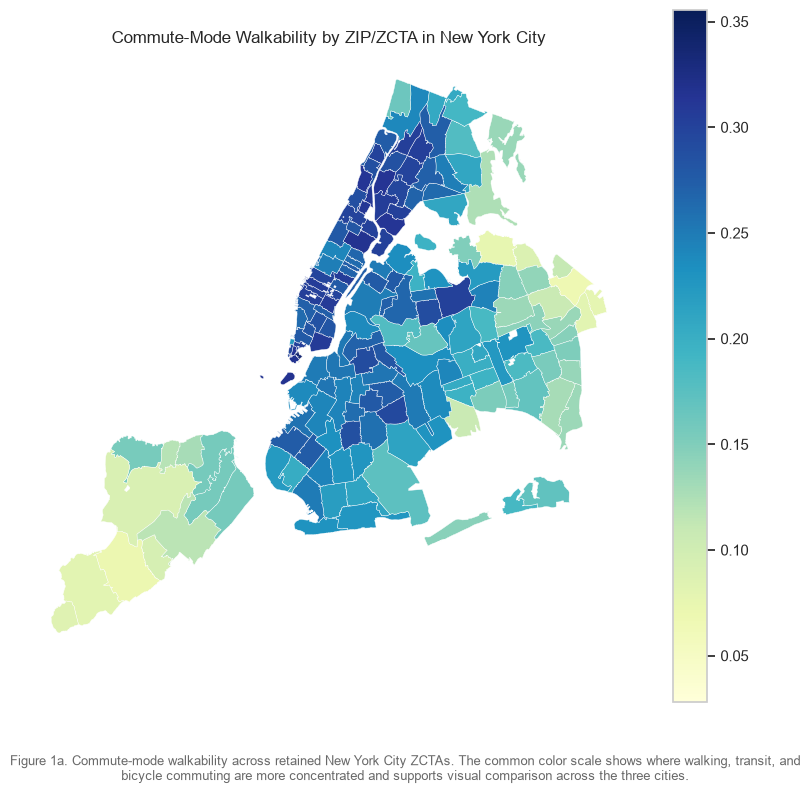

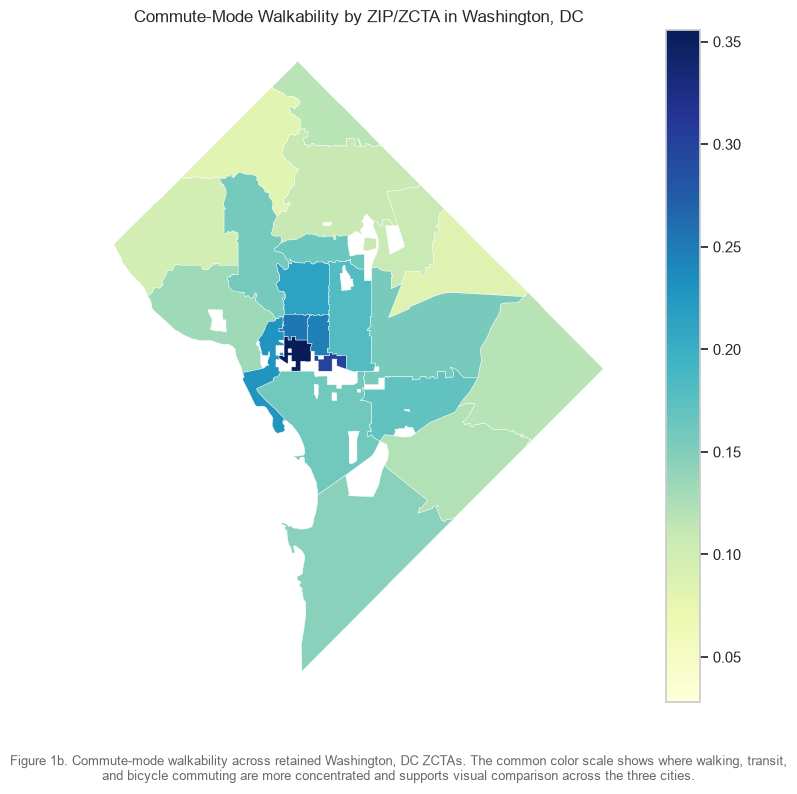

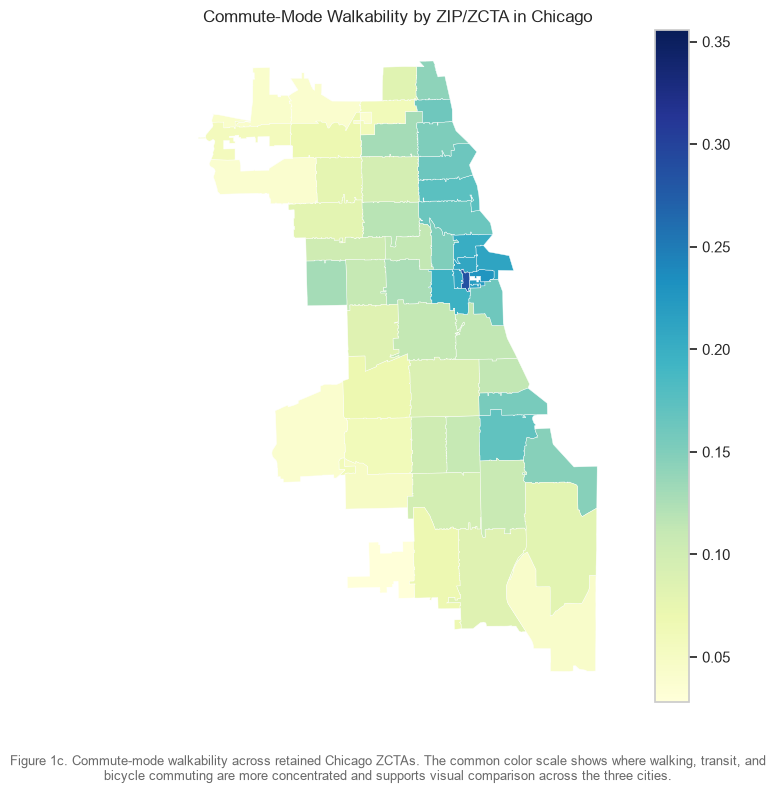

Mapped analysis rows: 248


In [59]:
# Load the manually downloaded national ZCTA shapefile used to map analysis ZIPs.
zcta_path = GEO_DIR / "tl_2024_us_zcta520.shp"
if not zcta_path.exists():
    raise FileNotFoundError(
        f"Missing ZCTA shapefile: {zcta_path}. "
        "Download and extract the national 2024 ZCTA archive described in README.md."
    )

zcta_gdf = gpd.read_file(zcta_path)
if "ZCTA5CE20" not in zcta_gdf.columns:
    raise ValueError(
        "The ZCTA shapefile does not contain the required ZCTA5CE20 field.")

# Normalize the geometry key and keep only shapes used by the retained analysis sample.
zcta_gdf["ZIP"] = zcta_gdf["ZCTA5CE20"].astype("string").str.zfill(5)
zcta_gdf = zcta_gdf.loc[
    zcta_gdf["ZIP"].isin(features_df["ZIP"]), ["ZIP", "geometry"]
].copy()

# Require one geometry for every retained ZIP so missing shapes cannot silently disappear.
if zcta_gdf["ZIP"].duplicated().any():
    raise ValueError("The selected ZCTA geometry contains duplicate ZIP rows.")
missing_zips = sorted(set(features_df["ZIP"]) - set(zcta_gdf["ZIP"]))
if missing_zips:
    raise ValueError(
        f"Missing ZCTA geometry for analysis ZIPs: {missing_zips[:10]}")

features_geo = zcta_gdf.merge(
    features_df, on="ZIP", how="inner", validate="one_to_one")
if len(features_geo) != len(features_df):
    raise ValueError("Geometry merge did not retain every analysis row.")

# Use one score range for all maps so the colors remain comparable across cities.
score_min = features_geo["Walkability_Score"].min()
score_max = features_geo["Walkability_Score"].max()
study_area_labels = {
    "New York City": ("New York City", "1a"),
    "Washington DC": ("Washington, DC", "1b"),
    "Chicago": ("Chicago", "1c"),
}

# Create one focused map per city because their geographic extents differ substantially.
for study_area, (display_name, figure_number) in study_area_labels.items():
    city_data = features_geo[features_geo["Study_Area"] == study_area]
    if city_data.empty:
        raise ValueError(f"No mapped rows found for {study_area}.")

    fig, ax = plt.subplots(figsize=(8, 8))
    city_data.plot(
        column="Walkability_Score",
        cmap="YlGnBu",
        linewidth=0.3,
        edgecolor="white",
        legend=True,
        vmin=score_min,
        vmax=score_max,
        ax=ax,
    )
    ax.set_title(f"Commute-Mode Walkability by ZIP/ZCTA in {display_name}")
    ax.set_axis_off()
    add_figure_caption(
        fig,
        f"Figure {figure_number}. Commute-mode walkability across retained {display_name} ZCTAs. "
        "The common color scale shows where walking, transit, and bicycle commuting are "
        "more concentrated and supports visual comparison across the three cities.",
    )
    fig.tight_layout(rect=(0, 0.09, 1, 1))
    plt.show()

print(f"Mapped analysis rows: {len(features_geo):,}")

## Mapping Result

All **248 retained observations** matched exactly one 2024 ZCTA geometry. The three maps use one common color scale, making between-city differences in the commute-mode proxy visible without changing the scale from one panel to another.

The maps describe ZCTAs rather than named neighborhoods. ZIP/ZCTA boundaries can cross or imperfectly approximate municipal boundaries, so spatial patterns should be interpreted at the study-area level defined in the introduction.

# Question 2: Does the Pooled Relationship Hold Within Cities?

This section compares the simple pooled relationship with city-controlled and city-specific estimates. The purpose is to test whether an apparent walkability–housing value relationship survives adjustment for geographic composition and selected socioeconomic characteristics. KMeans is retained as a secondary exploratory description of multivariate ZIP/ZCTA profiles.

=== Correlation Matrix ===
                      Log_ZHVI  Walkability_Score  Income_to_Rent  \
Log_ZHVI                  1.00               0.39            0.24   
Walkability_Score         0.39               1.00           -0.46   
Income_to_Rent            0.24              -0.46            1.00   
Home_Value_to_Income      0.46               0.56           -0.47   
Walk_Share                0.20               0.58           -0.05   
Transit_Share             0.32               0.78           -0.52   
Bike_Share                0.31               0.31            0.05   
Car_Share                -0.47              -0.93            0.26   
Commute_Min              -0.06              -0.09           -0.31   
Rent_Share                0.05               0.78           -0.60   
Owner_Share              -0.05              -0.78            0.60   
College_Grad_Share        0.38               0.22            0.47   
Population_k             -0.13               0.09           -0.31   

      

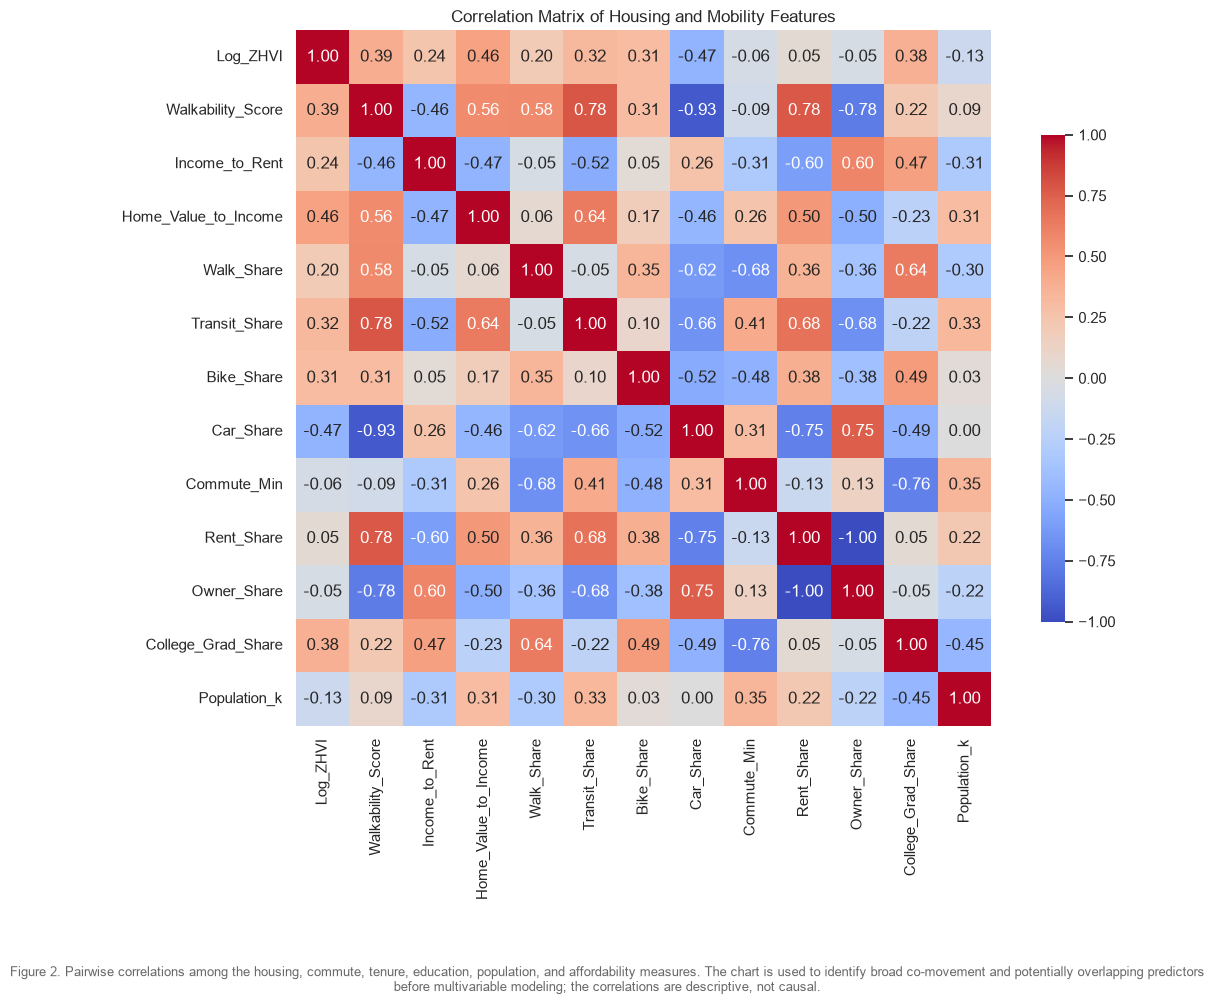

Primary OLS design matrix rank: 9/9

=== Primary OLS: Socioeconomic Predictors + City Indicators (HC3) ===
                            OLS Regression Results                            
Dep. Variable:               Log_ZHVI   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.776
Method:                 Least Squares   F-statistic:                     135.7
Date:                Tue, 18 Aug 2026   Prob (F-statistic):           2.17e-84
Time:                        12:07:49   Log-Likelihood:                -25.277
No. Observations:                 248   AIC:                             68.55
Df Residuals:                     239   BIC:                             100.2
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
----------

,Observations,Walkability_Coefficient,Walkability_Robust_p,R_Squared,Adjusted_R_Squared
Study_Area,,,,,
Chicago,55,-4.872,0.000,0.774,0.746
New York City,171,-0.976,0.213,0.537,0.520
Washington DC,22,-4.275,0.258,0.869,0.817



=== KMeans Cluster-Quality Diagnostics ===


,Inertia,Silhouette
k,,
2,618.00,0.345
3,406.99,0.381
4,320.50,0.355
5,278.65,0.321
6,248.50,0.290


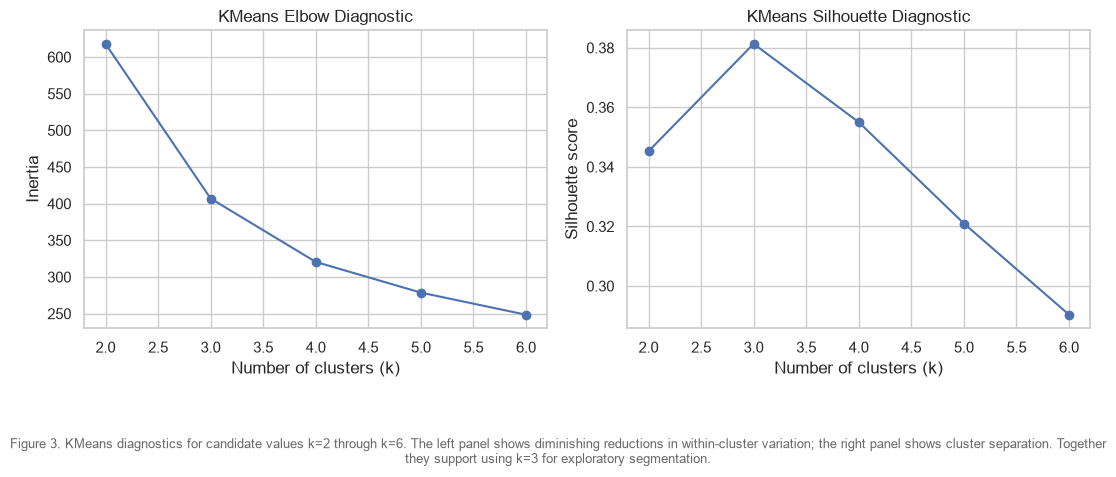

KMeans bootstrap stability (100 resamples): median ARI=0.900, 10th–90th percentile=0.818–0.980

=== Cluster Centroids (Original Scale) ===
   Walkability_Score  Income_to_Rent  Rent_Share  College_Grad_Share
0              0.235           4.575       0.658               0.784
1              0.250           3.187       0.761               0.325
2              0.115           4.684       0.390               0.361

=== Cluster Counts ===
Cluster
0    69
1    92
2    87
Name: count, dtype: int64

=== Cluster Summary Statistics ===
         Walkability_Score  Log_ZHVI  Income_to_Rent  Rent_Share  \
Cluster                                                            
0                    0.235    13.550           4.575       0.658   
1                    0.250    13.269           3.187       0.761   
2                    0.115    13.175           4.684       0.390   

         College_Grad_Share  
Cluster                      
0                     0.784  
1                     0.325  
2     

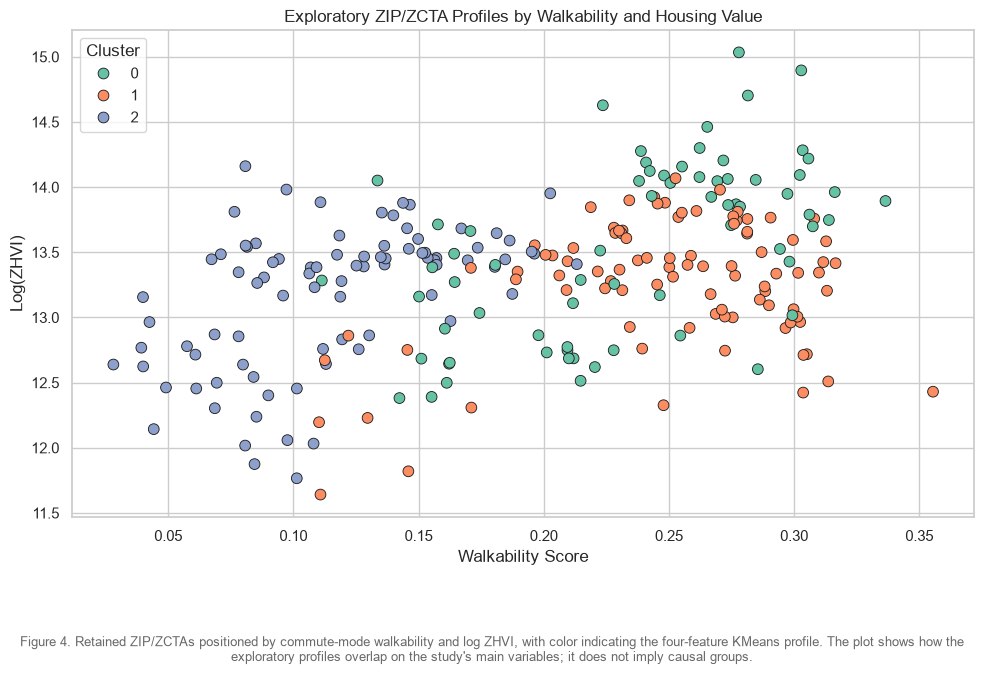

In [60]:
# Start from a deterministic analysis frame so every model uses identical row ordering.
df = features_df.sort_values(
    ["Study_Area", "ZIP"]).reset_index(drop=True).copy()

# Inspect pairwise relationships among the outcome, commute modes, tenure, and affordability measures.
selected_cols = [
    "Log_ZHVI", "Walkability_Score", "Income_to_Rent", "Home_Value_to_Income",
    "Walk_Share", "Transit_Share", "Bike_Share", "Car_Share",
    "Commute_Min", "Rent_Share", "Owner_Share", "College_Grad_Share", "Population_k",
]
corr = df[selected_cols].corr()

print("=== Correlation Matrix ===")
print(corr.round(2))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    cbar_kws={"shrink": 0.7},
    ax=ax,
)
ax.set_title("Correlation Matrix of Housing and Mobility Features")
add_figure_caption(
    fig,
    "Figure 2. Pairwise correlations among the housing, commute, tenure, education, "
    "population, and affordability measures. The chart is used to identify broad "
    "co-movement and potentially overlapping predictors before multivariable modeling; "
    "the correlations are descriptive, not causal.",
)
fig.tight_layout(rect=(0, 0.10, 1, 1))
plt.show()

# The primary OLS specification uses socioeconomic controls that do not directly contain ZHVI.
primary_predictors = [
    "Walkability_Score", "Log_Median_Income", "Commute_Min",
    "Rent_Share", "College_Grad_Share", "Log_Population",
]


def fit_robust_ols(data, predictors, *, include_study_area=False):
    """Fit a full-rank OLS model with HC3 robust standard errors."""
    # City indicators isolate within-sample differences from broad between-city levels.
    design = data[predictors].astype(float).copy()
    if include_study_area:
        indicators = pd.get_dummies(
            data["Study_Area"], prefix="Study_Area", drop_first=True, dtype=float
        )
        design = pd.concat([design, indicators], axis=1)

    # Add the intercept and reject a rank-deficient design before fitting the model.
    design = sm.add_constant(design, has_constant="add")
    rank = np.linalg.matrix_rank(design.to_numpy())
    if rank < design.shape[1]:
        raise ValueError(
            f"OLS design matrix is rank deficient: rank {rank} for {design.shape[1]} columns"
        )

    # HC3 errors make inference less sensitive to heteroskedastic residual variance.
    fitted = sm.OLS(data["Log_ZHVI"], design).fit(cov_type="HC3")
    return fitted, design


# Fit the main city-controlled model used to answer the primary research question.
primary_model, primary_design = fit_robust_ols(
    df, primary_predictors, include_study_area=True
)
print(
    "Primary OLS design matrix rank: "
    f"{np.linalg.matrix_rank(primary_design.to_numpy())}/{primary_design.shape[1]}"
)
print("\n=== Primary OLS: Socioeconomic Predictors + City Indicators (HC3) ===")
print(primary_model.summary())

# Add the ACS home-value ratio only as a sensitivity check because it overlaps with ZHVI.
sensitivity_predictors = [*primary_predictors, "Home_Value_to_Income"]
sensitivity_model, sensitivity_design = fit_robust_ols(
    df, sensitivity_predictors, include_study_area=True
)
print(
    "\nSensitivity OLS design matrix rank: "
    f"{np.linalg.matrix_rank(sensitivity_design.to_numpy())}/{sensitivity_design.shape[1]}"
)
print("\n=== Sensitivity OLS: Adds ACS Home-Value-to-Income Ratio (HC3) ===")
print(sensitivity_model.summary())

# Refit the primary specification within each city to expose geographic heterogeneity.
city_model_rows = []
for study_area, city_data in df.groupby("Study_Area", sort=True):
    city_model, _ = fit_robust_ols(city_data, primary_predictors)
    city_model_rows.append(
        {
            "Study_Area": study_area,
            "Observations": int(city_model.nobs),
            "Walkability_Coefficient": city_model.params["Walkability_Score"],
            "Walkability_Robust_p": city_model.pvalues["Walkability_Score"],
            "R_Squared": city_model.rsquared,
            "Adjusted_R_Squared": city_model.rsquared_adj,
        }
    )
city_model_summary = pd.DataFrame(city_model_rows).set_index("Study_Area")
city_model_display = city_model_summary.copy()
for column in [
    "Walkability_Coefficient", "Walkability_Robust_p",
    "R_Squared", "Adjusted_R_Squared",
]:
    city_model_display[column] = city_model_display[column].map(
        lambda value: f"{value:.3f}"
    )
print("\n=== City-Specific OLS Results ===")
display(city_model_display)

# Standardize four complementary features so no variable dominates KMeans by scale alone.
features_for_clustering = df[[
    "Walkability_Score", "Income_to_Rent", "Rent_Share", "College_Grad_Share"
]]
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(features_for_clustering)

# Compare candidate cluster counts using compactness (inertia) and separation (silhouette).
cluster_quality_rows = []
for candidate_k in range(2, 7):
    candidate_model = KMeans(n_clusters=candidate_k,
                             random_state=42, n_init=50)
    candidate_labels = candidate_model.fit_predict(cluster_scaled)
    cluster_quality_rows.append(
        {
            "k": candidate_k,
            "Inertia": candidate_model.inertia_,
            "Silhouette": silhouette_score(cluster_scaled, candidate_labels),
        }
    )
cluster_quality = pd.DataFrame(cluster_quality_rows).set_index("k")
cluster_quality_display = cluster_quality.copy()
cluster_quality_display["Inertia"] = cluster_quality_display["Inertia"].map(
    lambda value: f"{value:.2f}"
)
cluster_quality_display["Silhouette"] = cluster_quality_display["Silhouette"].map(
    lambda value: f"{value:.3f}"
)
print("\n=== KMeans Cluster-Quality Diagnostics ===")
display(cluster_quality_display)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].plot(cluster_quality.index, cluster_quality["Inertia"], marker="o")
axes[0].set(title="KMeans Elbow Diagnostic",
            xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(cluster_quality.index, cluster_quality["Silhouette"], marker="o")
axes[1].set(title="KMeans Silhouette Diagnostic",
            xlabel="Number of clusters (k)", ylabel="Silhouette score")
add_figure_caption(
    fig,
    "Figure 3. KMeans diagnostics for candidate values k=2 through k=6. The left panel "
    "shows diminishing reductions in within-cluster variation; the right panel shows "
    "cluster separation. Together they support using k=3 for exploratory segmentation.",
)
fig.tight_layout(rect=(0, 0.16, 1, 1))
plt.show()

# Fit the selected three-cluster solution used for profile summaries and visualization.
selected_k = 3
kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=50)
df["Cluster"] = kmeans.fit_predict(cluster_scaled)

# Bootstrap the rows and compare assignments with adjusted Rand index to assess stability.
bootstrap_rng = np.random.default_rng(42)
bootstrap_ari = []
reference_labels = df["Cluster"].to_numpy()
for bootstrap_iteration in range(100):
    sample_indices = bootstrap_rng.choice(len(df), size=len(df), replace=True)
    unique_indices = np.unique(sample_indices)
    if len(unique_indices) <= selected_k:
        continue
    bootstrap_model = KMeans(
        n_clusters=selected_k,
        random_state=1_000 + bootstrap_iteration,
        n_init=20,
    )
    bootstrap_labels = bootstrap_model.fit_predict(
        cluster_scaled[sample_indices])

    # Repeated rows can receive multiple labels, so use their modal bootstrap assignment.
    assignments = pd.DataFrame(
        {"Index": sample_indices, "Label": bootstrap_labels}
    ).groupby("Index")["Label"].agg(lambda labels: labels.mode().iat[0])
    compared_indices = assignments.index.to_numpy()
    bootstrap_ari.append(
        adjusted_rand_score(
            reference_labels[compared_indices], assignments.to_numpy())
    )
cluster_stability = pd.Series(bootstrap_ari, name="Adjusted_Rand_Index")
print(
    "KMeans bootstrap stability (100 resamples): "
    f"median ARI={cluster_stability.median():.3f}, "
    f"10th–90th percentile={cluster_stability.quantile(0.1):.3f}–"
    f"{cluster_stability.quantile(0.9):.3f}"
)

# Transform centroids back to original units so each cluster can be interpreted directly.
centroids_unscaled = pd.DataFrame(
    cluster_scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features_for_clustering.columns,
)
print("\n=== Cluster Centroids (Original Scale) ===")
print(centroids_unscaled.round(3))

print("\n=== Cluster Counts ===")
print(df["Cluster"].value_counts().sort_index())

print("\n=== Cluster Summary Statistics ===")
print(
    df.groupby("Cluster")[[
        "Walkability_Score", "Log_ZHVI", "Income_to_Rent",
        "Rent_Share", "College_Grad_Share",
    ]].mean().round(3)
)

# Plot cluster membership against the two variables most central to the research question.
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6.8))
sns.scatterplot(
    data=df,
    x="Walkability_Score",
    y="Log_ZHVI",
    hue="Cluster",
    palette="Set2",
    s=60,
    edgecolor="k",
    ax=ax,
)
ax.set_title("Exploratory ZIP/ZCTA Profiles by Walkability and Housing Value")
ax.set_xlabel("Walkability Score")
ax.set_ylabel("Log(ZHVI)")
ax.legend(title="Cluster", loc="upper left")
add_figure_caption(
    fig,
    "Figure 4. Retained ZIP/ZCTAs positioned by commute-mode walkability and log ZHVI, "
    "with color indicating the four-feature KMeans profile. The plot shows how the "
    "exploratory profiles overlap on the study's main variables; it does not imply causal groups.",
)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

## Relationship and Clustering Findings

### 1. Pooled versus within-city relationship

The pooled correlation between `Walkability_Score` and `Log_ZHVI` is `0.39`, but the corresponding within-city correlations are `0.11` in Chicago, `0.07` in New York City, and `-0.54` in Washington, DC. The positive pooled pattern therefore does not describe one consistent relationship shared by all three cities.

### 2. Primary OLS with city indicators

The primary specification models `Log_ZHVI` using the walkability proxy, log median income, commute time, renter share, college-graduate share, log population, and city indicators. It excludes the ACS home-value ratio from the primary predictor set because that variable contains a second measure of the outcome concept. HC3 heteroskedasticity-robust standard errors are used, and the design is full rank (`9/9`).

- `Walkability_Score` coefficient: `-1.9095`
- HC3 robust $p$-value: `0.001`
- $R^2$: `0.783`; adjusted $R^2$: `0.776`

Because the outcome is logged and the score is measured as a share-like index, a 0.01 increase in the score corresponds to an estimated difference of approximately $100(\exp(-1.9095 \times 0.01)-1)=-1.89\%$ in ZHVI, conditional on the included variables. This is an associational estimate, not a causal effect.

The negative conditional coefficient differs from the positive pooled correlation. After accounting for city, income, commute time, tenure, education, and population, the estimated association reverses direction. That reversal is evidence of aggregation and specification sensitivity—not evidence that walkability lowers housing values.

City-specific estimates also differ in magnitude and precision: Chicago `-4.872` ($p<0.001$), New York City `-0.976` ($p=0.213$), and Washington, DC `-4.275` ($p=0.258$). The Washington estimate is based on only 22 observations and should be interpreted cautiously.

### 3. Home-value-ratio sensitivity model

Adding `Home_Value_to_Income` raises adjusted $R^2$ to `0.890`, and the walkability coefficient remains negative (`-2.1320`, $p<0.001$). This model is a sensitivity check rather than the primary specification because the ACS home-value numerator overlaps with the ZHVI outcome concept.

### 4. Exploratory ZIP/ZCTA profiles

Among candidate values `k=2` through `k=6`, `k=3` has the strongest silhouette score (`0.381`) and a visible inertia improvement. The three clusters contain 69, 92, and 87 observations. Their centroids distinguish broadly lower-, middle-, and higher-walkability/socioeconomic profiles, but they are exploratory categories rather than neighborhood types or causal groupings.

Bootstrap resampling gives a median adjusted Rand index of `0.900` with a 10th–90th percentile range of `0.818–0.980`, indicating that the selected three-cluster partition is reasonably stable to row resampling. Stability does not establish that three clusters are a uniquely true representation of the cities.

# Question 3: Do the Relationships Transfer to Another City?

The Lasso analysis is treated as a geographic transfer test rather than another in-sample fit. Each outer fold holds out one entire city, while grouped inner folds select the penalty using only the other two cities. This design asks whether the measured relationships generalize beyond the places used to estimate them.

=== Leave-One-City-Out Lasso Performance ===


,Rows,Selected_Alpha,MAE,RMSE,R_Squared
Held_Out_City,,,,,
Chicago,55,0.2774,0.9484,1.0196,-6.4215
New York City,171,0.0119,0.9626,1.0155,-4.7642
Washington DC,22,0.0429,0.2988,0.3673,0.2859


Overall out-of-city performance: MAE=0.901, RMSE=0.976, R²=-1.879
Final city-grouped CV alpha: 0.02694
Standardized Lasso coefficients:
Rent_Share           -0.0000
College_Grad_Share   -0.0000
Log_Population        0.0465
Commute_Min           0.1085
Walkability_Score     0.2135
Log_Median_Income     0.3782


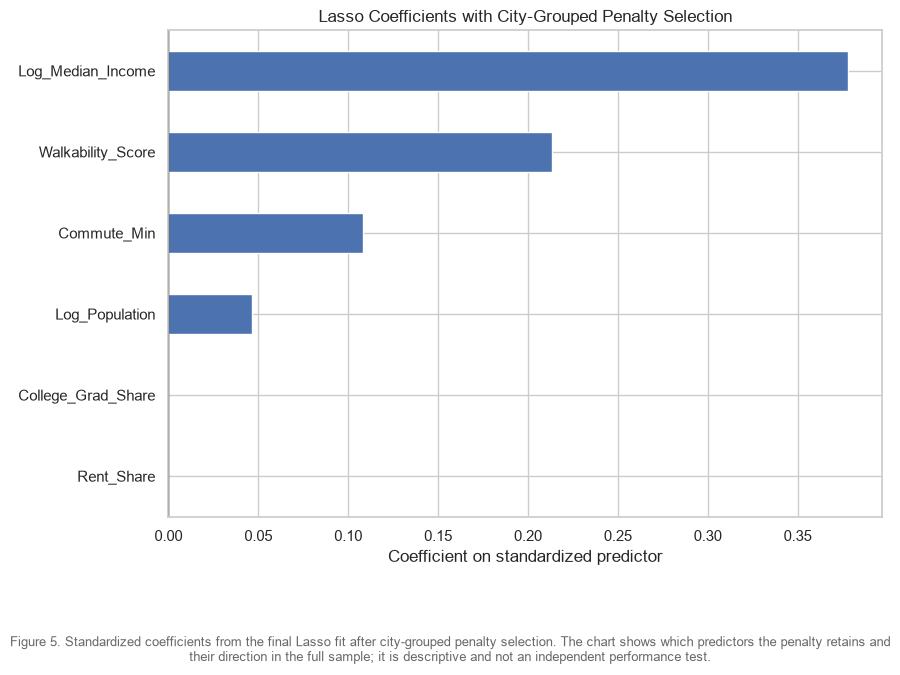

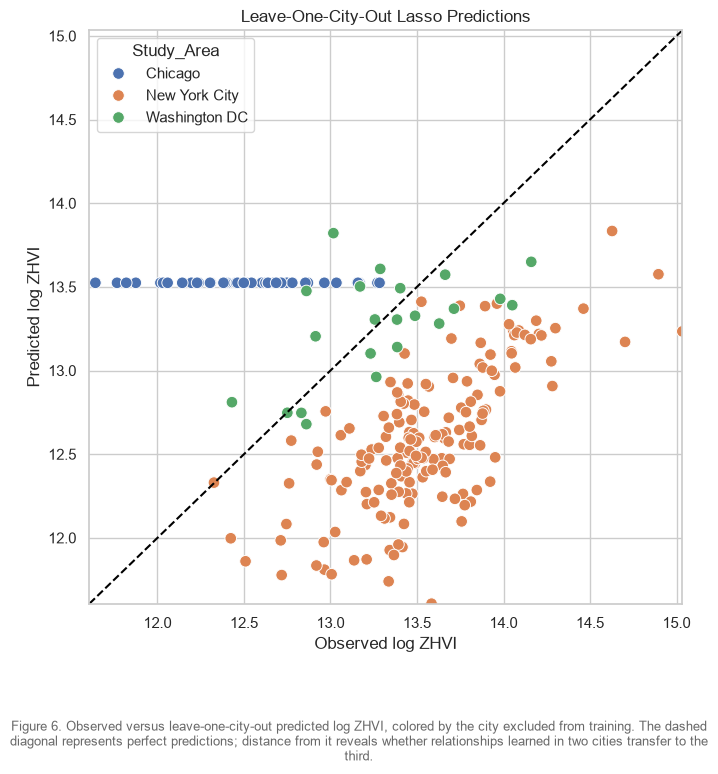

In [61]:
# Rebuild the ordered modeling frame and use only predictors available in every city.
df = features_df.sort_values(
    ["Study_Area", "ZIP"]).reset_index(drop=True).copy()
lasso_numeric_predictors = [
    "Walkability_Score",
    "Log_Median_Income",
    "Commute_Min",
    "Rent_Share",
    "College_Grad_Share",
    "Log_Population",
]
X_lasso = df[lasso_numeric_predictors].astype(float)
y_lasso = df["Log_ZHVI"].to_numpy()
groups = df["Study_Area"].to_numpy()

# The outer loop holds out one entire city; the inner loop selects alpha from the other two.
alphas = np.logspace(-4, 0, 80)
outer_cv = LeaveOneGroupOut()
outer_predictions = np.full(len(df), np.nan)
outer_fold_rows = []

for train_indices, test_indices in outer_cv.split(X_lasso, y_lasso, groups):
    train_groups = groups[train_indices]
    inner_cv = GroupKFold(n_splits=np.unique(train_groups).size)

    # Standardization occurs inside each fold to prevent information leakage before Lasso.
    pipeline = Pipeline(
        [
            ("scale", StandardScaler()),
            ("lasso", Lasso(max_iter=100_000)),
        ]
    )
    search = GridSearchCV(
        pipeline,
        param_grid={"lasso__alpha": alphas},
        scoring="neg_mean_squared_error",
        cv=inner_cv,
        n_jobs=-1,
    )
    search.fit(
        X_lasso.iloc[train_indices],
        y_lasso[train_indices],
        groups=train_groups,
    )

    # Store each held-out city's predictions and performance for one combined transfer test.
    fold_predictions = search.predict(X_lasso.iloc[test_indices])
    outer_predictions[test_indices] = fold_predictions
    held_out_city = groups[test_indices][0]
    outer_fold_rows.append(
        {
            "Held_Out_City": held_out_city,
            "Rows": len(test_indices),
            "Selected_Alpha": search.best_params_["lasso__alpha"],
            "MAE": mean_absolute_error(y_lasso[test_indices], fold_predictions),
            "RMSE": np.sqrt(mean_squared_error(y_lasso[test_indices], fold_predictions)),
            "R_Squared": r2_score(y_lasso[test_indices], fold_predictions),
        }
    )

# Every row must receive exactly one prediction from a model that did not train on its city.
if np.isnan(outer_predictions).any():
    raise RuntimeError(
        "At least one row did not receive an outer-fold prediction.")

# Format the per-city transfer metrics without changing the numeric evaluation results.
lasso_performance = pd.DataFrame(outer_fold_rows).set_index("Held_Out_City")
lasso_performance_display = lasso_performance.copy()
for column in ["Selected_Alpha", "MAE", "RMSE", "R_Squared"]:
    lasso_performance_display[column] = lasso_performance_display[column].map(
        lambda value: f"{value:.4f}"
    )

print("=== Leave-One-City-Out Lasso Performance ===")
display(lasso_performance_display)
print(
    "Overall out-of-city performance: "
    f"MAE={mean_absolute_error(y_lasso, outer_predictions):.3f}, "
    f"RMSE={np.sqrt(mean_squared_error(y_lasso, outer_predictions)):.3f}, "
    f"R²={r2_score(y_lasso, outer_predictions):.3f}"
)

# Select a final alpha with city-grouped folds, then fit all rows for coefficient interpretation.
full_inner_cv = GroupKFold(n_splits=df["Study_Area"].nunique())
final_lasso_search = GridSearchCV(
    Pipeline(
        [
            ("scale", StandardScaler()),
            ("lasso", Lasso(max_iter=100_000)),
        ]
    ),
    param_grid={"lasso__alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=full_inner_cv,
    n_jobs=-1,
)
final_lasso_search.fit(X_lasso, y_lasso, groups=groups)
final_lasso = final_lasso_search.best_estimator_.named_steps["lasso"]
coef_series = pd.Series(final_lasso.coef_, index=X_lasso.columns).sort_values()

print(
    f"Final city-grouped CV alpha: {final_lasso_search.best_params_['lasso__alpha']:.5f}")
print("Standardized Lasso coefficients:")
print(coef_series.round(4).to_string())

# Visualize the final standardized coefficients to compare direction and shrinkage.
fig, ax = plt.subplots(figsize=(9, 6.8))
coef_series.plot(kind="barh", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Lasso Coefficients with City-Grouped Penalty Selection")
ax.set_xlabel("Coefficient on standardized predictor")
add_figure_caption(
    fig,
    "Figure 5. Standardized coefficients from the final Lasso fit after city-grouped "
    "penalty selection. The chart shows which predictors the penalty retains and their "
    "direction in the full sample; it is descriptive and not an independent performance test.",
)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

# Pair each outer-fold prediction with its observed value for a direct transferability check.
prediction_results = df[["Study_Area", "ZIP", "Log_ZHVI"]].copy()
prediction_results["Predicted_Log_ZHVI"] = outer_predictions
plot_min = prediction_results[["Log_ZHVI", "Predicted_Log_ZHVI"]].min().min()
plot_max = prediction_results[["Log_ZHVI", "Predicted_Log_ZHVI"]].max().max()

fig, ax = plt.subplots(figsize=(7, 7.8))
sns.scatterplot(
    data=prediction_results,
    x="Log_ZHVI",
    y="Predicted_Log_ZHVI",
    hue="Study_Area",
    s=70,
    ax=ax,
)
ax.plot([plot_min, plot_max], [plot_min, plot_max],
        linestyle="--", color="black")
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)
ax.set_title("Leave-One-City-Out Lasso Predictions")
ax.set_xlabel("Observed log ZHVI")
ax.set_ylabel("Predicted log ZHVI")
add_figure_caption(
    fig,
    "Figure 6. Observed versus leave-one-city-out predicted log ZHVI, colored by the city "
    "excluded from training. The dashed diagonal represents perfect predictions; distance "
    "from it reveals whether relationships learned in two cities transfer to the third.",
)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

## Geographic Transfer Findings

### Leave-one-city-out validation

The nested validation design holds out each city in turn. Inner grouped folds choose the Lasso penalty without exposing the held-out city; the outer fold then measures how well relationships estimated in the other two cities transfer.

| Held-out city | Rows | MAE | RMSE | $R^2$ versus held-out mean |
|---|---:|---:|---:|---:|
| Chicago | 55 | 0.948 | 1.020 | -6.422 |
| New York City | 171 | 0.963 | 1.016 | -4.764 |
| Washington, DC | 22 | 0.299 | 0.367 | 0.286 |

Overall leave-one-city-out performance is MAE `0.901`, RMSE `0.976`, and $R^2=-1.879$. The model transfers better to Washington, DC than to Chicago or New York City, but the strongly negative overall $R^2$ means the combined transfer predictions are worse than predicting from the overall outcome mean.

The relationships measured by this feature set therefore do not generalize reliably from two cities to a geographically unseen third city. This is a central result: pooled fit and nonzero coefficients should not be presented as evidence of a universal urban housing relationship.

### Full-sample penalized coefficients

Using all observations with city-grouped penalty selection produces $\alpha=0.02694$. Standardized coefficients are:

- Log median income: `+0.3782`
- Walkability score: `+0.2135`
- Commute time: `+0.1085`
- Log population: `+0.0465`
- Renter share: `0.0000`
- College-graduate share: `0.0000`

These coefficients summarize a penalized fit on the full three-city sample; they are not independent performance estimates. The positive full-sample walkability coefficient coexists with poor geographic transfer and the negative city-controlled OLS coefficient, reinforcing the conclusion that the apparent relationship depends on geography and specification.

# Conclusion

## Answer to the primary question

**No single, stable walkability–housing value relationship holds across these three core-city samples.** The pooled data show a moderate positive correlation (`0.39`), but that pattern weakens or reverses when the cities are examined separately and when city context and selected socioeconomic characteristics are included.

The evidence is consistent across the notebook's main comparisons:

- Within-city correlations are `0.11` in Chicago, `0.07` in New York City, and `-0.54` in Washington, DC.
- In the primary city-controlled OLS model, the walkability coefficient is `-1.9095` with HC3 $p=0.001$; the model has $R^2=0.783$ and adjusted $R^2=0.776$.
- City-specific OLS estimates differ in magnitude and precision, so they do not support a general claim that the proxy is associated with uniformly higher or lower housing values.
- Nested leave-one-city-out Lasso validation performs poorly overall ($R^2=-1.879$), indicating that relationships estimated in two cities do not transfer reliably to the third.

The central finding is therefore **geographic heterogeneity and aggregation sensitivity**. Differences among New York City, Washington, DC, and Chicago materially shape the pooled result, and the direction of the conditional association also depends on model specification. None of the analyses establishes a causal effect of walkability on housing value.

## Secondary descriptive answers

- The sample-relative walkable-affordable screen identifies 51 of 248 ZIP/ZCTAs (20.6%). This is a reproducible comparison within the retained data, not an external affordability designation.
- The three-cluster KMeans solution is reasonably stable under row resampling, but it is best interpreted as exploratory segmentation of measured commute and socioeconomic profiles.

## Limitations and next steps

1. Replace the commute-mode proxy with independently validated built-environment measures such as destination access, street connectivity, land-use mix, or official walkability indices.
2. Add spatial dependence diagnostics or spatial regression because adjacent ZCTAs are unlikely to be statistically independent.
3. Test alternative city-boundary and metropolitan-area definitions to assess sensitivity to the modifiable areal unit problem.
4. Align housing and ACS observation periods more closely and use multiple years or longitudinal changes.
5. Expand the study to more cities before making broad claims about geographic generalization.